<div align="center">

# 🧠 Experiment 9: MNIST Classification Using Neural Networks

### Comparison of Activation Functions

*Implementation and Performance Comparison of Sigmoid, ReLU and Tanh Activation Functions using a Multi-Layer Perceptron (MLP) Classifier*

</div>

## 📊 1. Import the Required Libraries

---

The required Python libraries are imported for dataset handling, numerical operations, plotting, measuring execution time, splitting the dataset, building the neural network and evaluating classification accuracy.

In [13]:
import time

import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml

from sklearn.model_selection import train_test_split

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score

## 📥 2. Load the MNIST Dataset

---

The MNIST dataset contains handwritten digit images from 0 to 9. Each image is represented by 784 pixel values (28 × 28 pixels). The dataset is loaded using `fetch_openml()`.

The input data is stored in `X`, while the corresponding digit labels are stored in `y`. The values are converted to numeric data types for model processing.

In [14]:
                                                           

                       

                                                           

print("Loading MNIST dataset...")

X, y = fetch_openml(

    'mnist_784',

    version=1,

    return_X_y=True,

    as_frame=False

)

                         

X = X.astype('float32')

y = y.astype('int')

print("Dataset loaded successfully!")

print("Total samples:", X.shape[0])

print("Number of features:", X.shape[1])

Loading MNIST dataset...
Dataset loaded successfully!
Total samples: 70000
Number of features: 784


## ⚙️ 3. Preprocess the Dataset

---

Pixel values are normalized from the range 0–255 to 0–1 by dividing the input data by 255.

A subset of 20,000 samples is selected to reduce execution time. The dataset is then divided into training and testing sets using an 80:20 split. `stratify=y` maintains the distribution of digit classes in both sets.

In [15]:
                                                           

                           

                                                           

                                          

X = X / 255.0

                                           

X = X[:20000]

y = y[:20000]

                                      

X_train, X_test, y_train, y_test = train_test_split(

    X, y,

    test_size=0.2,

    random_state=42,

    stratify=y

)

print("\nTraining samples:", X_train.shape[0])

print("Testing samples:", X_test.shape[0])


Training samples: 16000
Testing samples: 4000


## 🎯 4. Define the Activation Functions

---

Three activation functions are considered for comparison:

- **Sigmoid (logistic):** Produces output values between 0 and 1.
- **ReLU:** Returns zero for negative inputs and the input itself for positive values.
- **Tanh:** Produces output values between -1 and 1.

The dictionaries are used to store the trained models, training times and classification accuracies for each activation function.

In [19]:
                                                           

                                

                                                           

activations = ['logistic', 'relu', 'tanh']

results = {}

training_times = {}

accuracies = {}

## 🧠 5. Train Neural Networks Using Different Activation Functions

---

An MLP (Multi-Layer Perceptron) classifier is trained separately using each activation function.

The network uses one hidden layer containing 128 neurons and the Adam optimizer. For every activation function, the following are recorded:

- Training time
- Number of iterations
- Test accuracy

The trained model and its performance values are stored for later comparison.

In [20]:
                                                           

                                                       

                                                           

for activation in activations:

    print("\n----------------------------------")

    print("Training with:", activation)

    print("----------------------------------")

    start_time = time.time()

    model = MLPClassifier(

        hidden_layer_sizes=(128,),

        activation=activation,

        solver='adam',

        max_iter=100,

        batch_size=128,

        random_state=42,

        verbose=False

    )

    model.fit(X_train, y_train)

    end_time = time.time()

                             

    training_time = end_time - start_time

                

    y_pred = model.predict(X_test)

              

    accuracy = accuracy_score(y_test, y_pred)

                   

    results[activation] = model

    training_times[activation] = training_time

    accuracies[activation] = accuracy * 100

    print("Training time: {:.2f} seconds".format(training_time))

    print("Number of iterations:", model.n_iter_)

    print("Test accuracy: {:.2f}%".format(accuracy * 100))


----------------------------------
Training with: logistic
----------------------------------
Training time: 15.58 seconds
Number of iterations: 99
Test accuracy: 95.58%

----------------------------------
Training with: relu
----------------------------------
Training time: 9.63 seconds
Number of iterations: 57
Test accuracy: 96.08%

----------------------------------
Training with: tanh
----------------------------------
Training time: 10.40 seconds
Number of iterations: 61
Test accuracy: 95.80%


## 📋 6. Display the Activation Function Comparison

---

The comparison table displays the training time, number of iterations and test accuracy obtained using Sigmoid, ReLU and Tanh.

This makes it easier to compare the performance of the three activation functions using the same dataset and model configuration.

In [7]:
                                                           

                             

                                                           

print("\n==========================================")

print("       ACTIVATION FUNCTION COMPARISON")

print("==========================================")

print("{:<12} {:<15} {:<15} {:<15}".format(

    "Activation", "Time (sec)", "Iterations", "Accuracy (%)"

))

for activation in activations:

    model = results[activation]

    print("{:<12} {:<15.2f} {:<15} {:<15.2f}".format(

        activation,

        training_times[activation],

        model.n_iter_,

        accuracies[activation]

    ))


       ACTIVATION FUNCTION COMPARISON
Activation   Time (sec)      Iterations      Accuracy (%)   
logistic     20.67           99              95.58          
relu         11.97           57              96.08          
tanh         10.05           61              95.80          


## 📈 7. Visualize Accuracy Comparison

---

A bar graph is plotted to compare the classification accuracy of the three activation functions.

The X-axis represents the activation functions, while the Y-axis represents classification accuracy in percentage. The accuracy values are also displayed above the bars.

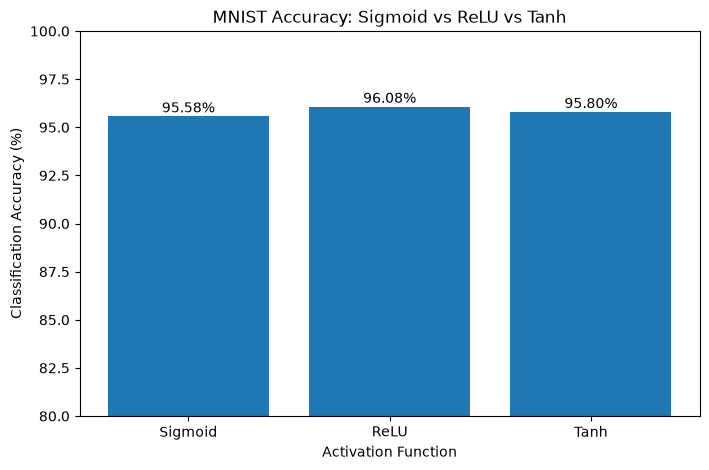

In [8]:
                                                           

                              

                                                           

plt.figure(figsize=(8, 5))

plt.bar(

    ['Sigmoid', 'ReLU', 'Tanh'],

    [

        accuracies['logistic'],

        accuracies['relu'],

        accuracies['tanh']

    ]

)

plt.xlabel("Activation Function")

plt.ylabel("Classification Accuracy (%)")

plt.title("MNIST Accuracy: Sigmoid vs ReLU vs Tanh")

plt.ylim(80, 100)

                         

for i, value in enumerate([

    accuracies['logistic'],

    accuracies['relu'],

    accuracies['tanh']

]):

    plt.text(i, value + 0.2, f"{value:.2f}%",

             ha='center')

plt.show()

## ⏱️ 8. Visualize Training Time Comparison

---

A bar graph is plotted to compare the time required to train the neural network using each activation function.

The graph helps identify which activation function takes less time to train under the selected configuration.

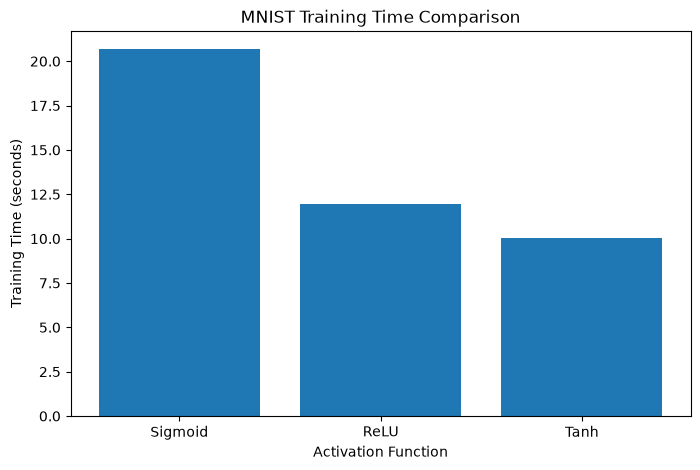

In [9]:


                                                           

                                   

                                                           

plt.figure(figsize=(8, 5))

plt.bar(

    ['Sigmoid', 'ReLU', 'Tanh'],

    [

        training_times['logistic'],

        training_times['relu'],

        training_times['tanh']

    ]

)

plt.xlabel("Activation Function")

plt.ylabel("Training Time (seconds)")

plt.title("MNIST Training Time Comparison")

plt.show()

## 📉 9. Compare Convergence

---

The loss curve of each trained model is plotted against the number of iterations.

The loss curve shows how the model's loss changes during training. A decreasing loss generally indicates that the model is learning from the training data. Comparing the curves helps observe the convergence behaviour of Sigmoid, ReLU and Tanh.

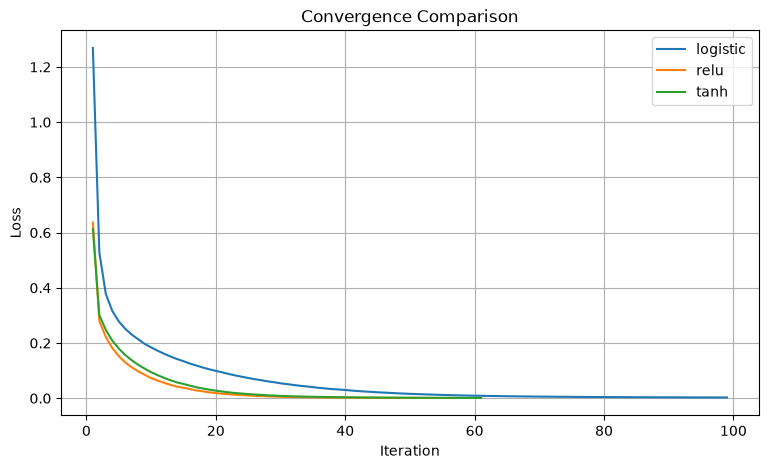

In [21]:
                                                           

                           

                                                           

plt.figure(figsize=(9, 5))

for activation in activations:

    model = results[activation]

    plt.plot(

        range(1, len(model.loss_curve_) + 1),

        model.loss_curve_,

        label=activation

    )

plt.xlabel("Iteration")

plt.ylabel("Loss")

plt.title("Convergence Comparison")

plt.legend()

plt.grid(True)

plt.show()